<a href="https://colab.research.google.com/github/henryhkb/ecg-vision-app/blob/main/ECG_Vision_03_Robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
# drive: connects Colab to your Google Drive
from google.colab import drive
drive.mount('/content/drive')

# os: file paths | numpy: arrays of numbers | pandas: tables | matplotlib: plots
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
# torch: PyTorch, the deep learning library | nn: its neural-network building blocks
import torch
import torch.nn as nn
# models: ready-made architectures such as ResNet-18 | transforms: image changes (resize, blur, rotate...)
from torchvision import models, transforms
# Image: opens PNG files | Dataset/DataLoader: feed images to the model in batches
from PIL import Image
from torch.utils.data import Dataset, DataLoader
# f1_score/recall_score/confusion_matrix: the scores we use
from sklearn.metrics import f1_score, recall_score, confusion_matrix

# Paths, same as notebook 02
PROJECT_DIR = '/content/drive/MyDrive/ECG_Vision_App'
DATA_DIR = os.path.join(PROJECT_DIR, 'data')
MODEL_DIR = os.path.join(PROJECT_DIR, 'models')
IMG_DIR = '/content/ecg_images'

# Unzip the ECG images from Drive into Colab (skips files already there)
!unzip -q -n {DATA_DIR}/ecg_images.zip -d /content

# Load the labels and keep only the validation ECGs
data = pd.read_csv(os.path.join(DATA_DIR, 'af_vs_normal_labels.csv'), index_col='ecg_id')
val_table = data[data['split'] == 'val']

# Use the GPU
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# Rebuild the same ResNet-18 shape as notebook 02, then load your trained weights (epoch 3)
model = models.resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 1)
model.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'resnet18_best.pt'), map_location=device))
model = model.to(device).eval()

print('Validation ECGs:', len(val_table), '| device:', device)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Validation ECGs: 992 | device: cuda


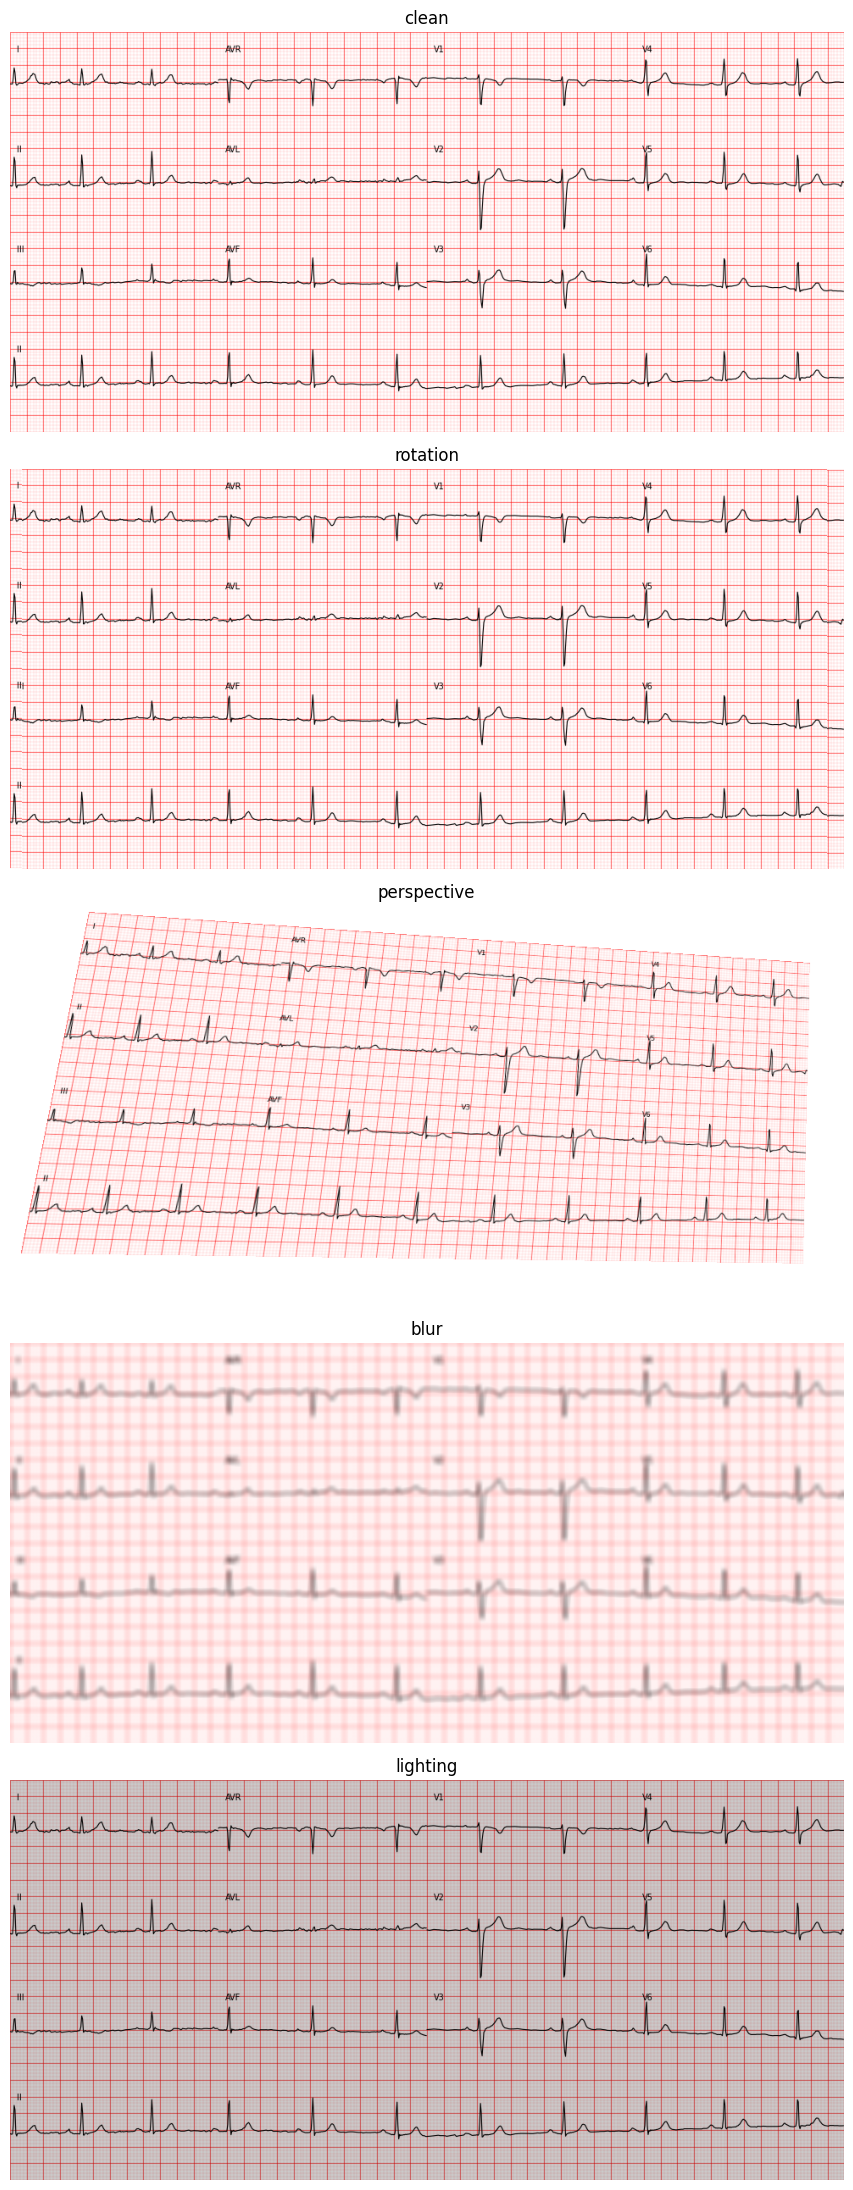

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
# The same preparation as in training: resize, convert to numbers, rescale like ImageNet
IMG_SIZE = (240, 496)
to_model = transforms.Compose([
    transforms.Resize(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

# Photo-like distortions, each imitating a real problem with phone photos
distortions = {
    'clean':       transforms.Lambda(lambda img: img),                         # no change
    'rotation':    transforms.RandomRotation(degrees=8, fill=255),             # phone held slightly tilted
    'perspective': transforms.RandomPerspective(distortion_scale=0.3, p=1.0, fill=255),  # photo taken at an angle
    'blur':        transforms.GaussianBlur(kernel_size=9, sigma=3),            # out of focus / shaky hand
    'lighting':    transforms.ColorJitter(brightness=0.5, contrast=0.5),       # dim room, flash, uneven light
}

# Show one validation ECG under each distortion
img = Image.open(f'{IMG_DIR}/{val_table.index[0]}.png').convert('RGB')
torch.manual_seed(0)   # fixes the random distortions so you get the same pictures each run
fig, axes = plt.subplots(len(distortions), 1, figsize=(12, 22))
for ax, (name, d) in zip(axes, distortions.items()):
    ax.imshow(d(img))
    ax.set_title(name)
    ax.axis('off')
# Save the whole figure (all 5 versions) as one PNG file, in Colab and on your Drive
plt.tight_layout()                                   # removes extra empty space between the images
save_path = os.path.join(PROJECT_DIR, 'distortions_example.png')
plt.savefig(save_path, dpi=80)                       # dpi 80 keeps the file small enough to attach
plt.show()

# files.download sends a file from Colab to your computer's Downloads folder
from google.colab import files
files.download(save_path)

In [10]:
# A Dataset that applies one distortion to each image before preparing it for the model
class DistortedDataset(Dataset):
    def __init__(self, table, distortion):
        self.ids = table.index.tolist()              # ECG IDs
        self.labels = table['label'].tolist()        # 0 = Normal, 1 = AF
        self.distortion = distortion                 # which distortion to apply
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        img = Image.open(f'{IMG_DIR}/{self.ids[i]}.png').convert('RGB')
        img = self.distortion(img)                   # 1. distort the image
        return to_model(img), torch.tensor(self.labels[i], dtype=torch.float32)  # 2. prepare it as in training

# Predict AF probabilities without learning (same idea as predict() in notebook 02)
def predict(loader):
    probs, labels = [], []
    with torch.no_grad():                                        # no learning, just predictions
        for images, y in loader:
            logits = model(images.to(device)).squeeze(1)         # raw AF scores
            probs.append(torch.sigmoid(logits).cpu())            # turn them into probabilities (0 to 1)
            labels.append(y)
    return torch.cat(probs).numpy(), torch.cat(labels).numpy().astype(int)

THRESHOLD = 0.30     # the threshold you chose in notebook 02

# Score the model on the 992 validation ECGs under each distortion
rows = []
for name, d in distortions.items():
    torch.manual_seed(0)                                         # same random distortions every run
    loader = DataLoader(DistortedDataset(val_table, d), batch_size=32, shuffle=False, num_workers=2)
    probs, labels = predict(loader)
    preds = (probs >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds).ravel()
    rows.append({'distortion': name,
                 'missed_AF': fn,
                 'false_alarms': fp,
                 'sensitivity': round(recall_score(labels, preds), 3),
                 'specificity': round(recall_score(labels, preds, pos_label=0), 3),
                 'F1': round(f1_score(labels, preds), 3)})
    print('done:', name)

robust = pd.DataFrame(rows)
print(robust.to_string(index=False))

done: clean
done: rotation
done: perspective
done: blur
done: lighting
 distortion  missed_AF  false_alarms  sensitivity  specificity    F1
      clean          3             6        0.980        0.993 0.970
   rotation          2           304        0.987        0.639 0.493
perspective          0           764        1.000        0.092 0.283
       blur          0           841        1.000        0.000 0.264
   lighting          2           303        0.987        0.640 0.494


In [ ]:
# RandomApply: applies a change only some of the time (here 50%),
# so the model also keeps seeing clean images, not only distorted ones
train_augment = transforms.Compose([
    transforms.RandomApply([transforms.RandomRotation(degrees=8, fill=255)], p=0.5),                      # tilt
    transforms.RandomApply([transforms.RandomPerspective(distortion_scale=0.3, p=1.0, fill=255)], p=0.5),  # photo taken at an angle
    transforms.RandomApply([transforms.GaussianBlur(kernel_size=9, sigma=(0.1, 3.0))], p=0.5),            # blur, random strength
    transforms.RandomApply([transforms.ColorJitter(brightness=0.5, contrast=0.5)], p=0.5),                # lighting
])

# Preview: the same training ECG, augmented 4 times; each time a different random mix of changes
train_table = data[data['split'] == 'train']
img = Image.open(f'{IMG_DIR}/{train_table.index[0]}.png').convert('RGB')
fig, axes = plt.subplots(4, 1, figsize=(12, 18))
for i, ax in enumerate(axes):
    ax.imshow(train_augment(img))
    ax.set_title(f'augmented version {i + 1}')
    ax.axis('off')
plt.tight_layout()

# Save the picture to Drive and download it, so you can attach it here
save_path = os.path.join(PROJECT_DIR, 'augmentation_example.png')
plt.savefig(save_path, dpi=80)
plt.show()
from google.colab import files
files.download(save_path)

In [ ]:
# time: measures each epoch
import time

# Training images: augment first (random tilt/angle/blur/lighting), then prepare as usual
class TrainDataset(Dataset):
    def __init__(self, table):
        self.ids = table.index.tolist()
        self.labels = table['label'].tolist()
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, i):
        img = Image.open(f'{IMG_DIR}/{self.ids[i]}.png').convert('RGB')
        img = train_augment(img)                              # a different random version every epoch
        return to_model(img), torch.tensor(self.labels[i], dtype=torch.float32)

train_loader = DataLoader(TrainDataset(train_table), batch_size=32, shuffle=True, num_workers=2)
# Validation stays clean (no augmentation), exactly like notebook 02, for a fair comparison
val_loader = DataLoader(DistortedDataset(val_table, distortions['clean']), batch_size=32, shuffle=False, num_workers=2)

# A NEW model: fresh pretrained ResNet-18, NOT the old trained one
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
model.fc = nn.Linear(model.fc.in_features, 1)
model = model.to(device)

# Same loss (AF mistakes weighted 5.41x, from the training set) and same optimiser as notebook 02
n_normal = (train_table['label'] == 0).sum()
n_af = (train_table['label'] == 1).sum()
loss_fn = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([n_normal / n_af], device=device))
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

EPOCHS = 8               # more than before: varied images are harder to learn from
best_f1 = -1
save_path = os.path.join(MODEL_DIR, 'resnet18_augmented_best.pt')   # new file; the old model is kept

for epoch in range(1, EPOCHS + 1):
    start = time.time()
    # 1. LEARN from augmented training images
    model.train()
    total_loss = 0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(images).squeeze(1), labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
    # 2. CHECK on clean validation images (no learning)
    model.eval()
    probs, labels = predict(val_loader)
    preds = (probs >= 0.5).astype(int)
    f1 = f1_score(labels, preds)
    print(f'Epoch {epoch}: train loss {total_loss / len(train_table):.3f} | val F1 {f1:.3f} | '
          f'sensitivity {recall_score(labels, preds):.3f} | '
          f'specificity {recall_score(labels, preds, pos_label=0):.3f} | {time.time() - start:.0f}s')
    # 3. SAVE if best so far
    if f1 > best_f1:
        best_f1 = f1
        torch.save(model.state_dict(), save_path)
        print('   ✓ new best model saved to Drive')

In [11]:
# Load the BEST augmented model (epoch 2) from Drive
model.load_state_dict(torch.load(os.path.join(MODEL_DIR, 'resnet18_augmented_best.pt'), map_location=device))
model.eval()

# Same robustness test as Cell 3: same 992 validation ECGs, same distortions, same threshold
rows = []
for name, d in distortions.items():
    torch.manual_seed(0)                                   # identical random distortions to the "before" table
    loader = DataLoader(DistortedDataset(val_table, d), batch_size=32, shuffle=False, num_workers=2)
    probs, labels = predict(loader)
    preds = (probs >= THRESHOLD).astype(int)
    tn, fp, fn, tp = confusion_matrix(labels, preds).ravel()
    rows.append({'distortion': name, 'missed_AF': fn, 'false_alarms': fp,
                 'sensitivity': round(recall_score(labels, preds), 3),
                 'specificity': round(recall_score(labels, preds, pos_label=0), 3),
                 'F1': round(f1_score(labels, preds), 3)})

robust_after = pd.DataFrame(rows)
print('AFTER augmentation:')
print(robust_after.to_string(index=False))

AFTER augmentation:
 distortion  missed_AF  false_alarms  sensitivity  specificity    F1
      clean          2            12        0.987        0.986 0.955
   rotation          3             5        0.980        0.994 0.974
perspective         10             3        0.934        0.996 0.956
       blur          1            35        0.993        0.958 0.893
   lighting          2            29        0.987        0.966 0.906


In [12]:
# 1. Get the new model's AF probabilities ONCE for each version of the validation set
#    (clean + 4 distortions), so we can try many thresholds quickly without re-running the model
all_probs = {}
for name, d in distortions.items():
    torch.manual_seed(0)                                   # same distortions as the tables above
    loader = DataLoader(DistortedDataset(val_table, d), batch_size=32, shuffle=False, num_workers=2)
    all_probs[name], val_labels = predict(loader)

# 2. Try thresholds 0.05, 0.10 ... 0.95 and score each one
rows = []
for t in np.arange(0.05, 1.0, 0.05):
    row = {'threshold': round(t, 2)}
    f1s = []
    for name in distortions:
        preds = (all_probs[name] >= t).astype(int)
        f1s.append(f1_score(val_labels, preds))
        if name == 'clean':                                # counts for clean images
            tn, fp, fn, tp = confusion_matrix(val_labels, preds).ravel()
            row['clean_missed_AF'] = fn
            row['clean_false_alarms'] = fp
            row['clean_F1'] = round(f1s[-1], 3)
    row['worst_F1'] = round(min(f1s), 3)                   # the hardest version (usually blur)
    row['average_F1'] = round(np.mean(f1s), 3)             # average over clean + 4 distortions
    rows.append(row)

thr_table = pd.DataFrame(rows)
print(thr_table.to_string(index=False))
print('\nBest threshold by average F1:', thr_table.loc[thr_table['average_F1'].idxmax(), 'threshold'])

 threshold  clean_missed_AF  clean_false_alarms  clean_F1  worst_F1  average_F1
      0.05                1                  49     0.857     0.696       0.840
      0.10                2                  25     0.917     0.785       0.892
      0.15                2                  20     0.931     0.833       0.910
      0.20                2                  16     0.943     0.860       0.921
      0.25                2                  14     0.949     0.882       0.929
      0.30                2                  12     0.955     0.893       0.937
      0.35                2                  11     0.958     0.904       0.943
      0.40                3                  10     0.958     0.909       0.945
      0.45                3                   6     0.970     0.920       0.949
      0.50                4                   6     0.967     0.926       0.952
      0.55                4                   5     0.970     0.925       0.954
      0.60                4             

In [13]:
# The test set: 967 ECGs (fold 10) that no model has learned from and no decision was based on
test_table = data[data['split'] == 'test']
NEW_THRESHOLD = 0.45      # chosen on validation; don't change it after seeing these results

def score_test(weights_file, threshold):
    """Load one model's saved weights, then score it on the clean and distorted test sets."""
    model.load_state_dict(torch.load(os.path.join(MODEL_DIR, weights_file), map_location=device))
    model.eval()
    rows = []
    for name, d in distortions.items():
        torch.manual_seed(0)                                     # same kind of distortions as on validation
        loader = DataLoader(DistortedDataset(test_table, d), batch_size=32, shuffle=False, num_workers=2)
        probs, labels = predict(loader)
        preds = (probs >= threshold).astype(int)
        tn, fp, fn, tp = confusion_matrix(labels, preds).ravel()
        rows.append({'distortion': name, 'missed_AF': fn, 'false_alarms': fp,
                     'sensitivity': round(recall_score(labels, preds), 3),
                     'specificity': round(recall_score(labels, preds, pos_label=0), 3),
                     'F1': round(f1_score(labels, preds), 3)})
    return pd.DataFrame(rows)

# Old model (clean training, its threshold 0.30) for comparison, then the new augmented model at 0.45
old_test = score_test('resnet18_best.pt', 0.30)
new_test = score_test('resnet18_augmented_best.pt', NEW_THRESHOLD)

print('TEST SET, OLD model (clean training, threshold 0.30):')
print(old_test.to_string(index=False))
print('\nTEST SET, NEW model (augmented training, threshold 0.45):')
print(new_test.to_string(index=False))

TEST SET, OLD model (clean training, threshold 0.30):
 distortion  missed_AF  false_alarms  sensitivity  specificity    F1
      clean          6             4        0.961        0.995 0.967
   rotation          2           292        0.987        0.642 0.505
perspective          0           737        1.000        0.096 0.292
       blur          0           815        1.000        0.000 0.272
   lighting          2           277        0.987        0.660 0.518

TEST SET, NEW model (augmented training, threshold 0.45):
 distortion  missed_AF  false_alarms  sensitivity  specificity    F1
      clean          6             8        0.961        0.990 0.954
   rotation          6             6        0.961        0.993 0.961
perspective         15             1        0.901        0.999 0.945
       blur          4            23        0.974        0.972 0.916
   lighting          5            17        0.967        0.979 0.930
